# Benchmark Results Analysis 

## Setup

In [22]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [23]:
RESULTS_PATH = Path("results/Qwen3-8B_eval.csv")
results = pd.read_csv(RESULTS_PATH)

### Setting defaults

In [24]:
# Names
metric_tuples = [
    ('top10_jaccard', 'Top-10 Jaccard', '$\\uparrow$'),
    # ('top20_jaccard', 'Top-20 Jaccard', '$\\uparrow$'),
    ('top20pct_overlap', 'Top-20% Overlap', '$\\uparrow$'),
    # ('top40pct_overlap', 'Top-40% Overlap', '$\\uparrow$'),
    ('kendall_tau', 'Kendall\'s $\\tau$', '$\\uparrow$')
]

metrics = [met[0] for met in metric_tuples]
metrics_formatted = [met[1] for met in metric_tuples]
metric_directions = [met[2] for met in metric_tuples]

In [25]:
# Seaborn defaults
bg_color = "#FAF9F6"
grid_color = "#E5E4E2"
sns.set(rc={
    'axes.facecolor':bg_color, 
    'figure.facecolor':bg_color,
    'grid.color': grid_color,
    'axes.edgecolor': grid_color,
    'lines.markeredgecolor': grid_color,
    'scatter.edgecolors': grid_color,
})
sns.set_palette("Set2")
# Font
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": "DejaVu Sans",
})

## Data Cleaning

In [26]:
results[['metro_id', 'policy', 'prompt_id']] = pd.DataFrame(results['item_id'].str.split('_').to_list(), index=results.index)

## Analysis

In [27]:
results.head(3)

,pid,item_id,canon,prompt,query,level,error,kendall_tau,top10_jaccard,top20_jaccard,top20pct_overlap,top40pct_overlap,metro_id,policy,prompt_id
0,AUS_P1_0_og,AUS_P1_0,True,Which census tracts in the Austin-Round Rock-S...,"SELECT census_tracts.GEOID, RFLD_RISKS AS scor...",L2,NaN,0.621342,0.111111,0.250000,0.125249,0.302187,AUS,P1,0
1,AUS_P1_0_pp,AUS_P1_0,False,Which census tracts in the Austin-Round Rock-S...,"SELECT census_tracts.GEOID, (nri.RFLD_RISKS + ...",L2,NaN,0.571332,0.111111,0.142857,0.111332,0.290258,AUS,P1,0
2,AUS_P1_1_og,AUS_P1_1,True,Which census tracts in the Austin-Round Rock-S...,"SELECT census_tracts.GEOID, RFLD_EXPA AS score...",L1,<class '_duckdb.BinderException'>,NaN,NaN,NaN,NaN,NaN,AUS,P1,1


In [28]:
results[metrics].describe()

,top10_jaccard,top20pct_overlap,kendall_tau
count,156.000000,135.000000,119.000000
mean,0.143427,0.093627,0.457852
std,0.253864,0.053908,0.313614
min,0.000000,0.000000,-0.138773
25%,0.000000,0.052787,0.214765
50%,0.000000,0.087441,0.468194
75%,0.176471,0.132775,0.660336
max,1.000000,0.199876,1.000000


In [29]:
results.groupby(['level', 'canon'])['top10_jaccard'].mean()

level  canon
L0     False    0.236647
       True     0.156196
L1     False    0.072385
       True     0.195658
L2     False    0.052643
       True     0.115721
Name: top10_jaccard, dtype: float64

### Plotting

Text(0.5, 1.0, 'Evaluation Metrics by Policy (Qwen3-8B)')

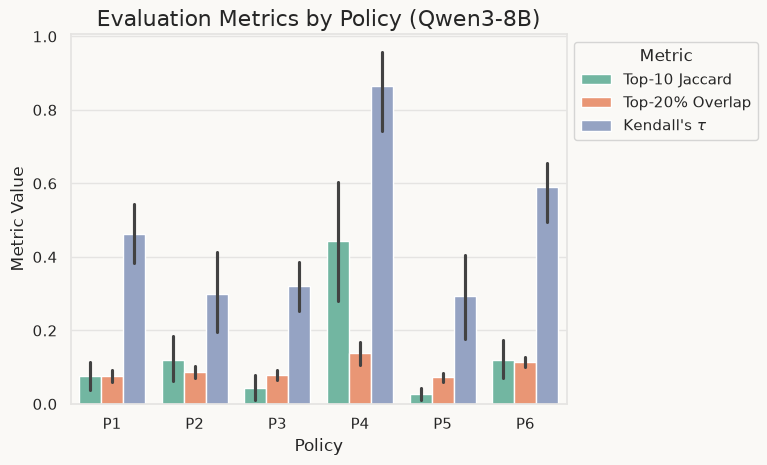

In [32]:
temp = results.copy(deep=True)
# temp[metrics] = MinMaxScaler().fit_transform(X=temp[metrics])

ax = sns.barplot(
    temp[metrics + ['policy']].melt('policy', var_name='metric'),
    x='policy',
    y='value',
    hue='metric'
)
ax.set_xlabel("Policy")
ax.set_ylabel("Metric Value")
# format legend with metrics and metrics_formatted
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, metrics_formatted, title="Metric", bbox_to_anchor=(1, 1))
ax.set_title(
    "Evaluation Metrics by Policy (Qwen3-8B)",
    fontsize=16
)

Text(0.5, 1.0, 'Difference in Metrics between Prompt Phrasings')

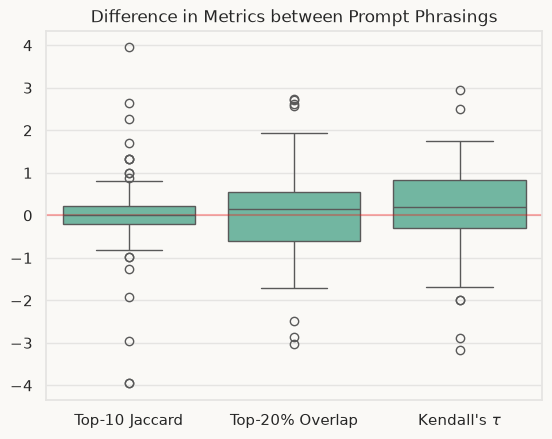

In [31]:
temp = results.copy(deep=True)
temp[metrics] = StandardScaler().fit_transform(X=temp[metrics])

para_diffs = temp.groupby('canon')[metrics].diff()
# sns.boxplot(para_diffs., bins=20)
ax = sns.boxplot(
    para_diffs.melt(var_name = 'metric'),
    x='metric', y='value',
    )

ax.set_xticks(ticks=metrics, labels=metrics_formatted)
ax.set_ylabel("")
ax.set_xlabel("")
ax.axhline(y=0, color='red', alpha=0.3)
ax.set_title("Difference in Metrics between Prompt Phrasings")